# 03 — Build and check the simulated human

**Goal:** build a pretend teacher from the real training records and check how closely it matches them. Run 00–02 first, with the **Project (.venv)** kernel.

Short notebook cells call reusable Python files. Plain-language notes explain each step; the implementation is in [calib.py](../src/sim/calib.py), [validation.py](../src/sim/validation.py),
and [difficulty.py](../src/learn/difficulty.py). The simulator privately owns true labels and person parameters. Controllers never receive them. Held-out person profiles are stored privately to define later simulated people; only training people are used in these calibration plots and checks. Final-test image answers are excluded. This is an internal calibration check, not independent evidence of real human fatigue.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
from src.common import save_run, load_calibration, load_contexts
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})

def show_plot(name):
    plt.tight_layout()
    plt.savefig(folder / f'{name}.png', dpi=150)
    plt.show()

## 1. Fit picture difficulty, person skill, speed, and mistakes
Skill describes a person's usual correctness after accounting for picture easiness. We fit one skill number and one normal-speed profile per person. We also count which wrong categories people choose. The time equation includes slower errors and practice.

In [2]:
from src.sim.calib import fit_calibration, validate_simulator
from src.sim.validation import validation_checks, session_slopes
calibration, real_records = fit_calibration()
folder = save_run('sim_validation', {'seed': 42, 'scope': 'training people; development images',
    'validation': 'full labels; no fatigue effect; rare lapse process enabled'})
print('Training records used:', len(real_records))

Training records used: 246895


## 2. Check the calibration parameters
Histograms show training people only. A long tail of weaker people is kept rather than replaced by a neat bell-shaped distribution. Parameters describe differences between people; they are not visible to the decision-making controller.

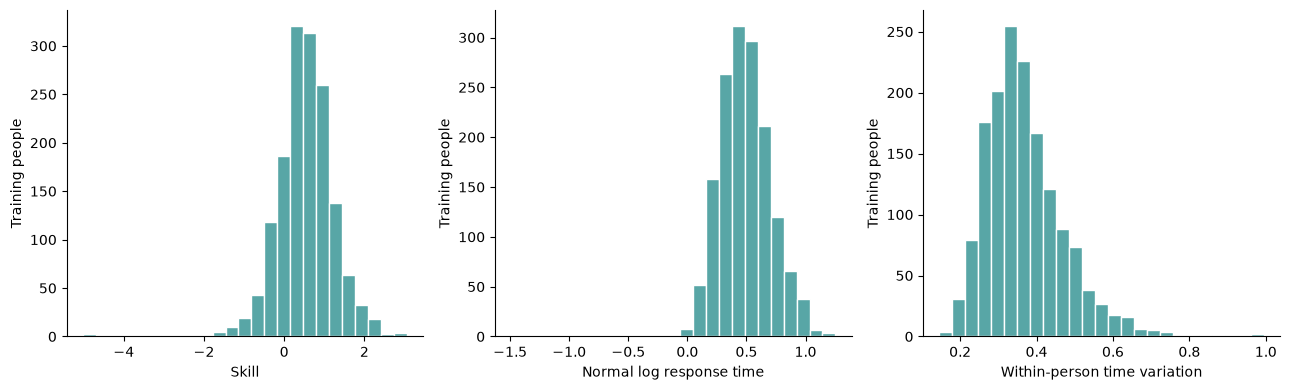

In [3]:
training_people = calibration['person_split'] == 'train'
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, key, label in zip(axes, ['theta', 'mu', 'sigma'], ['Skill', 'Normal log response time', 'Within-person time variation']):
    ax.hist(calibration[key][training_people], bins=25, color='#58a6a6', edgecolor='white')
    ax.set(xlabel=label, ylabel='Training people')
show_plot('01_training_person_profiles')

## 3. Fix our checks before comparing
A basic simulator is acceptable if accuracy is within 1 percentage point, median time and
log-time spread within 15%, wrong/correct time ratio within 20%, mean slope within
0.5 percentage points per 100 trials, slope spread within 25%, and confusion rank
correlation at least 0.8. A separate large draw should put lapse onset within 0.15 percentage
points of 0.6% over 200 questions. These are coarse development tolerances.
They do not establish that the fatigue assumptions are true.

In [4]:
simulated_records, lapse_onsets = validate_simulator(calibration, real_records, seed=42)
checks, real_records = validation_checks(real_records, simulated_records, calibration)
checks.to_csv(folder / 'validation_checks.csv', index=False)
display(checks.round(4))

,check,real,simulated,allowed_absolute_difference,passed
0,accuracy,0.9491,0.9463,0.0100,True
1,median_seconds,1.4900,1.5943,0.2235,True
2,log_time_sd,0.4635,0.4658,0.0695,True
3,wrong_correct_time_ratio,1.5020,1.6608,0.3004,True
4,mean_slope_pp_per_100,-0.2488,-0.2903,0.5000,True
5,slope_sd,3.7409,4.5029,0.9352,True
6,confusion_rank_correlation,1.0000,0.9830,0.2000,True
7,lapse_onset_rate_200_trials,0.0060,0.0062,0.0015,True


## 4. Compare answer times
The left plot includes the full cleaned range. The right compares the middle of each distribution by answer correctness.

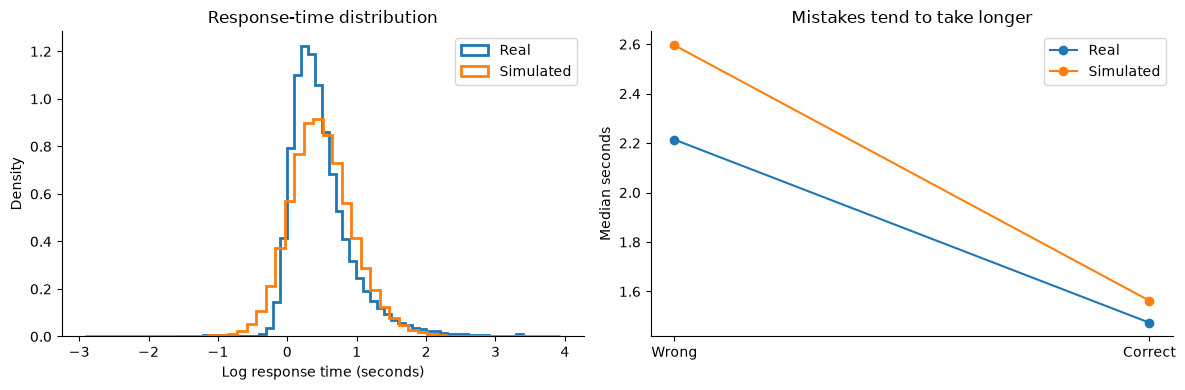

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, records in [('Real', real_records), ('Simulated', simulated_records)]:
    axes[0].hist(np.log(records.response_seconds), bins=50, density=True, histtype='step', linewidth=2, label=name)
    medians = records.groupby('correct_guess').response_seconds.median()
    axes[1].plot(['Wrong', 'Correct'], medians.reindex([0, 1]), 'o-', label=name)
axes[0].set(xlabel='Log response time (seconds)', ylabel='Density', title='Response-time distribution')
axes[1].set(ylabel='Median seconds', title='Mistakes tend to take longer')
for ax in axes:
    ax.legend()
show_plot('02_real_and_simulated_answer_times')

## 5. Compare session patterns and person-to-person drift
A **slope** describes whether performance rises or falls during a session. Shuffling each person's difficulty-adjusted answers removes their time ordering. The shuffled distribution helps show how much variation can arise by chance.

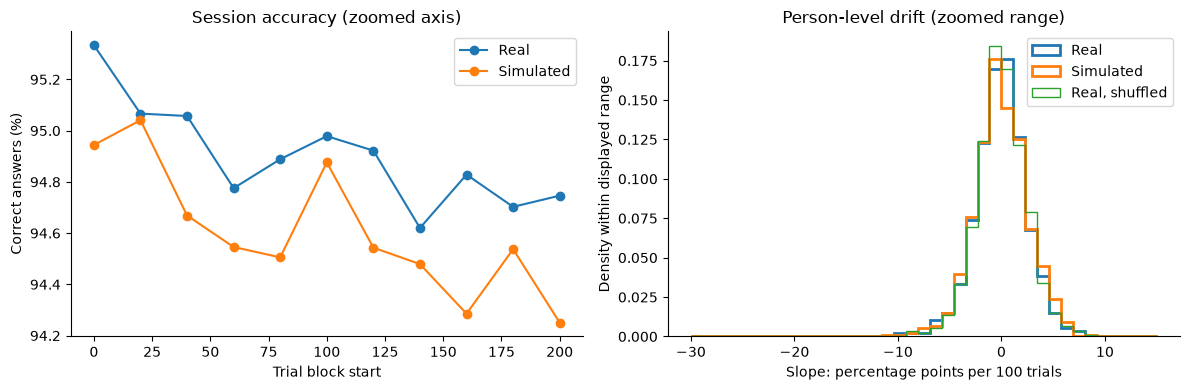

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, records in [('Real', real_records), ('Simulated', simulated_records)]:
    by_block = records.groupby(records.trial_index // 20).correct_guess.mean() * 100
    axes[0].plot(by_block.index * 20, by_block, 'o-', label=name)
    slopes = session_slopes(records, calibration['difficulty'])
    axes[1].hist(slopes, bins=np.linspace(-30, 15, 40), histtype='step', density=True, linewidth=2, label=name)
shuffled = session_slopes(real_records, calibration['difficulty'], shuffle=True)
axes[1].hist(shuffled, bins=np.linspace(-30, 15, 40), histtype='step', density=True, label='Real, shuffled')
axes[0].set(xlabel='Trial block start', ylabel='Correct answers (%)', title='Session accuracy (zoomed axis)')
axes[1].set(xlabel='Slope: percentage points per 100 trials', ylabel='Density within displayed range', title='Person-level drift (zoomed range)')
for ax in axes:
    ax.legend()
show_plot('03_session_accuracy_and_drift')

## 6. Compare common mistakes
The simulator uses real error patterns. A good match here is a calibration check, because these records also helped build it.

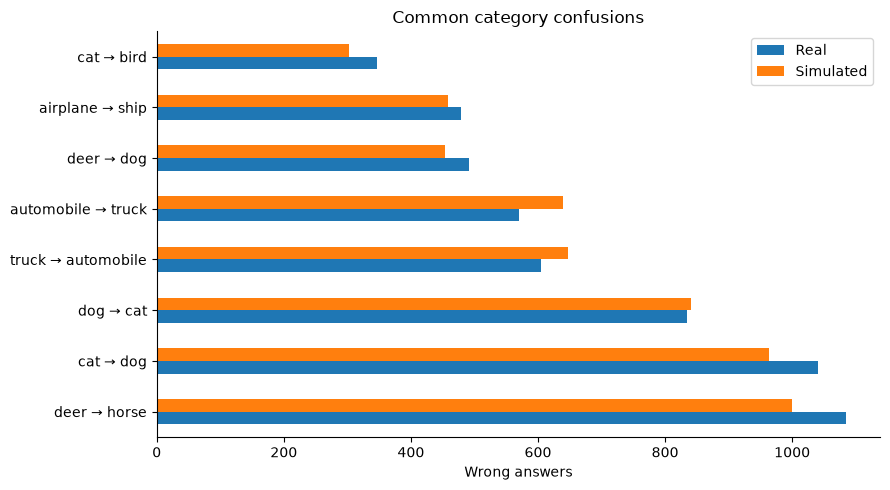

In [7]:
def error_counts(records):
    wrong = records[records.correct_guess == 0]
    return wrong.groupby(['true_label', 'chosen_label']).size()
common = error_counts(real_records).sort_values(ascending=False).head(8).index
comparison = pd.DataFrame({'Real': error_counts(real_records).reindex(common),
    'Simulated': error_counts(simulated_records).reindex(common)})
names = pd.read_csv(project / 'data/splits/images.csv').sort_values('true_label').drop_duplicates('true_label').true_category.tolist()
comparison.index = [f'{names[a]} → {names[b]}' for a, b in common]
comparison.plot.barh(figsize=(9, 5))
plt.xlabel('Wrong answers')
plt.title('Common category confusions')
show_plot('04_common_confusions')

## 7. Learn a difficulty prediction that the controller may see
Higher `d` means easier. A small neural network predicts `d` from image features. It trains only on the 2,000 separate difficulty-training images. We move this component forward from the original Stage-2 plan because Stage-1 controllers need deployable inputs too. Validation pictures check the prediction; pool difficulty is not supplied to controllers.

,value
Predictor validation MSE,1.099247
Constant prediction validation MSE,1.115730


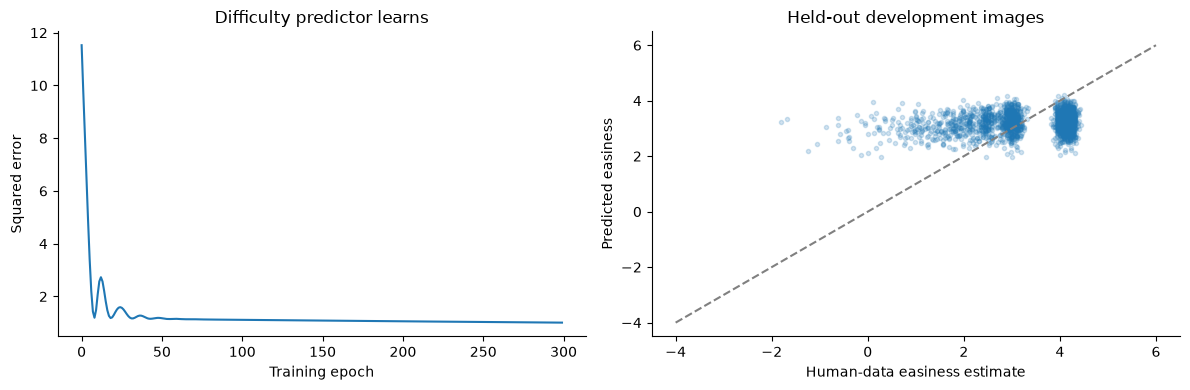

In [8]:
from src.learn.difficulty import train_difficulty_predictor
predictions, difficulty_losses = train_difficulty_predictor(calibration)
image_roles = pd.read_csv(project / 'data/splits/images.csv').set_index('image_id')
validation_ids = image_roles.index[image_roles.image_split == 'validation'].to_numpy()
estimated_d = predictions.set_index('image_id').loc[validation_ids, 'predicted_d'].to_numpy()
observed_d = calibration['difficulty'][validation_ids]
baseline_d = calibration['difficulty'][image_roles.index[image_roles.image_split == 'difficulty_train']].mean()
display(pd.Series({'Predictor validation MSE': np.mean((estimated_d - observed_d) ** 2),
    'Constant prediction validation MSE': np.mean((baseline_d - observed_d) ** 2)}).to_frame('value'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(difficulty_losses)
axes[0].set(xlabel='Training epoch', ylabel='Squared error', title='Difficulty predictor learns')
axes[1].scatter(observed_d, estimated_d, s=9, alpha=.2)
axes[1].plot([-4, 6], [-4, 6], '--', color='gray')
axes[1].set(xlabel='Human-data easiness estimate', ylabel='Predicted easiness', title='Held-out development images')
show_plot('05_difficulty_prediction')

## 8. Pass the development gate
A failed check stops later notebooks. A pass means these basic calibration tolerances were met. Fatigue strength, response-time clues, recovery, and easy-question bonuses still contain assumptions that we must stress-test.

In [9]:
gate = {'passed': bool(checks.passed.all()), 'checks_file': str((folder / 'validation_checks.csv').relative_to(project)),
    'checks': int(len(checks)), 'validation_scope': 'internal training-data calibration, coarse tolerances'}
(project / 'outputs/sim_validation/gate.json').write_text(json.dumps(gate, indent=2))
assert gate['passed'], 'Fix the failed simulator checks before controller experiments.'
print('All basic calibration checks passed. Continue to Notebook 04.')

All basic calibration checks passed. Continue to Notebook 04.


**What this gives us:** a reusable simulator calibration and a separate predicted-difficulty table. The raw data supports baseline skill, speed, and confusions. It does not establish our hypothetical fatigue curves. Held-out image evaluation remains untouched.